# 系统的性质：能否实时运行、稳定与恢复

对应笔记：`../../../系统的性质.md`。所有数据在本地合成，无需下载。先运行准备单元，再按顺序运行；修改各节开头参数即可重复实验。

目标：用图像和数值验证公式，并理解公式能解决什么问题。数值验证只覆盖所选案例，不代替数学证明。

**绘图约定：** 离散序列、采样测量与 DFT/FFT 频点采用竖杆图，样本之间不连线；连续时间或连续频率模型用曲线。各分量与结果分开成图，子图标题说明角色。较长序列会展示注明范围的局部，计算仍使用完整数据。

**学习方法：** 每节先读“要理解什么”与数学等式，把公式左右两边对应到代码及子图，再看计算误差或反例。重点是解释公式；实际应用用于帮助理解。数值近似、有限案例、理论恒等式和广义函数极限在各节分别说明。

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, integrate
from IPython.display import display, Markdown
rng = np.random.default_rng(42)
plt.rcParams.update({'figure.figsize': (9, 3), 'axes.grid': True})
# 图中使用英文标签，避免系统缺少中文字体；讲解和结果说明使用中文。
def graph(x, curves, xlabel='Sample index n', ylabel='Amplitude', *, kind='discrete', xlim=None):
    """每个分量独占子图；离散样本不连线，连续模型用曲线。"""
    import matplotlib.ticker as ticker
    count = len(curves)
    cols = min(2, count)
    rows = (count + cols - 1) // cols
    fig = plt.figure(figsize=(12 if cols == 2 else 10, 2.8 * rows), layout='constrained')
    grid = fig.add_gridspec(rows, cols)
    x = np.asarray(x)
    axes = []
    for i, (label, values) in enumerate(curves.items()):
        # 奇数个分量时，最后的结果图占满一行。
        slot = grid[i // cols, :] if count % 2 and i == count - 1 else grid[i // cols, i % cols]
        ax = fig.add_subplot(slot)
        values = np.asarray(values)
        color = f'C{i % 10}'
        if kind == 'discrete':
            marker, stems, baseline = ax.stem(x, values, basefmt='k-')
            plt.setp(marker, color=color, markersize=3 if len(x)>80 else 5)
            plt.setp(stems, color=color, linewidth=0.8 if len(x)>80 else 1.5)
            plt.setp(baseline, linewidth=0.5)
            if np.allclose(x, np.round(x)):
                ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=12, integer=True))
            if len(x) <= 20:
                ax.set_xticks(x)
                for xi, yi in zip(x, values):
                    if abs(yi) > max(1e-12, 0.05 * np.max(np.abs(values))):
                        ax.annotate(f'{yi:.3g}', (xi, yi), xytext=(0, 6 if yi >= 0 else -12),
                                    textcoords='offset points', ha='center', fontsize=8)
            ax.margins(y=0.2)
        elif kind == 'continuous':
            ax.plot(x, values, color=color, linewidth=1.5)
        else:
            raise ValueError('kind must be discrete or continuous')
        ax.set(title=label, xlabel=xlabel, ylabel=ylabel)
        if xlim is not None:
            ax.set_xlim(xlim)
        ax.grid(True, alpha=0.25)
        ax.set_axisbelow(True)
        axes.append(ax)
    plt.show()
    return axes

def err(a, b):
    return float(np.max(np.abs(np.asarray(a)-np.asarray(b))))


## 实验 1：线性：混音与失真

**要理解什么：** 理解线性就是“先混合再处理”和“分别处理再混合”得到相同结果。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{T\{ax_1(t)+bx_2(t)\}=ay_1(t)+by_2(t)},\quad y_i=T\{x_i\} \\[6pt]
\text{离散： }T\{ax_1[n]+bx_2[n]\}=aT\{x_1[n]\}+bT\{x_2[n]\}
\end{gathered}
$$

**符号与代码怎样对应：** 笔记先用连续 t 书写，本例按相同定义测试离散 n。`lhs` 是等式左边，`rhs` 是右边；分别测试 T(x)=3x 和 T(x)=x²，分量图展示 a*x1、b*x2 与各自经过系统的结果。

**怎样读图、怎样判断结果：** 固定增益的误差应接近零，平方器应有非零误差。最后的总和是两条输出分量之和，不能把输入分量和输出分量混加。一次失败是反例；有限次通过不能证明一般线性。

**先预测，再改参数：** 把平方器换成限幅，观察输入幅度较小时与发生削顶后，叠加误差如何变化。

**本例设置与适用范围：**

覆盖第一节线性。检查 $T(ax_1+bx_2)=aT(x_1)+bT(x_2)$；有限案例可以反驳性质，不能证明所有输入下成立。

gain 叠加误差： 8.881784197001252e-16


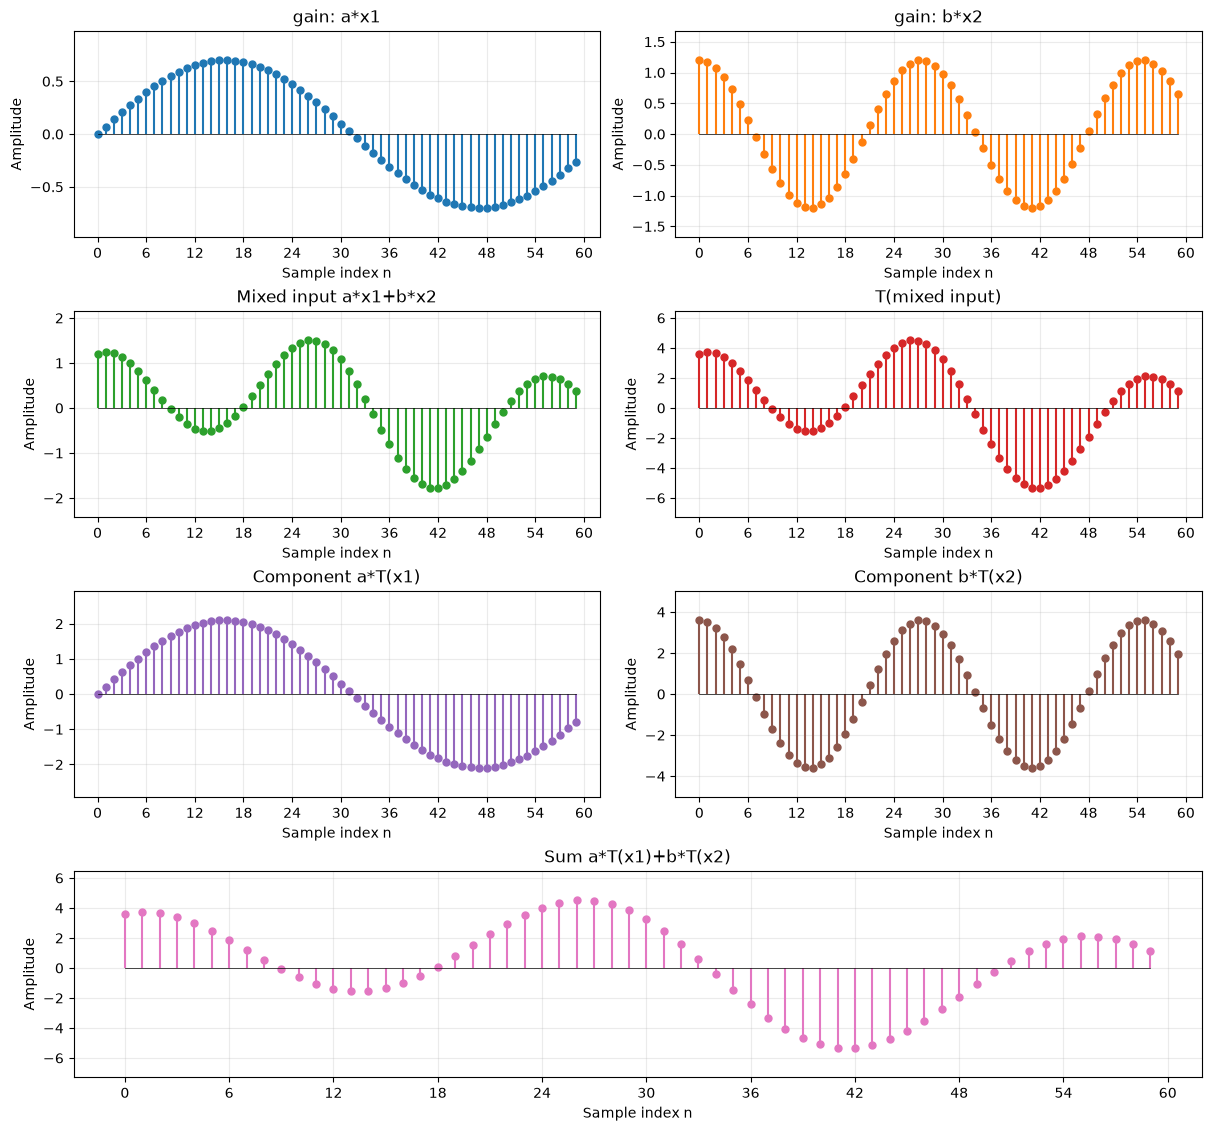

square 叠加误差： 1.6380735599226646


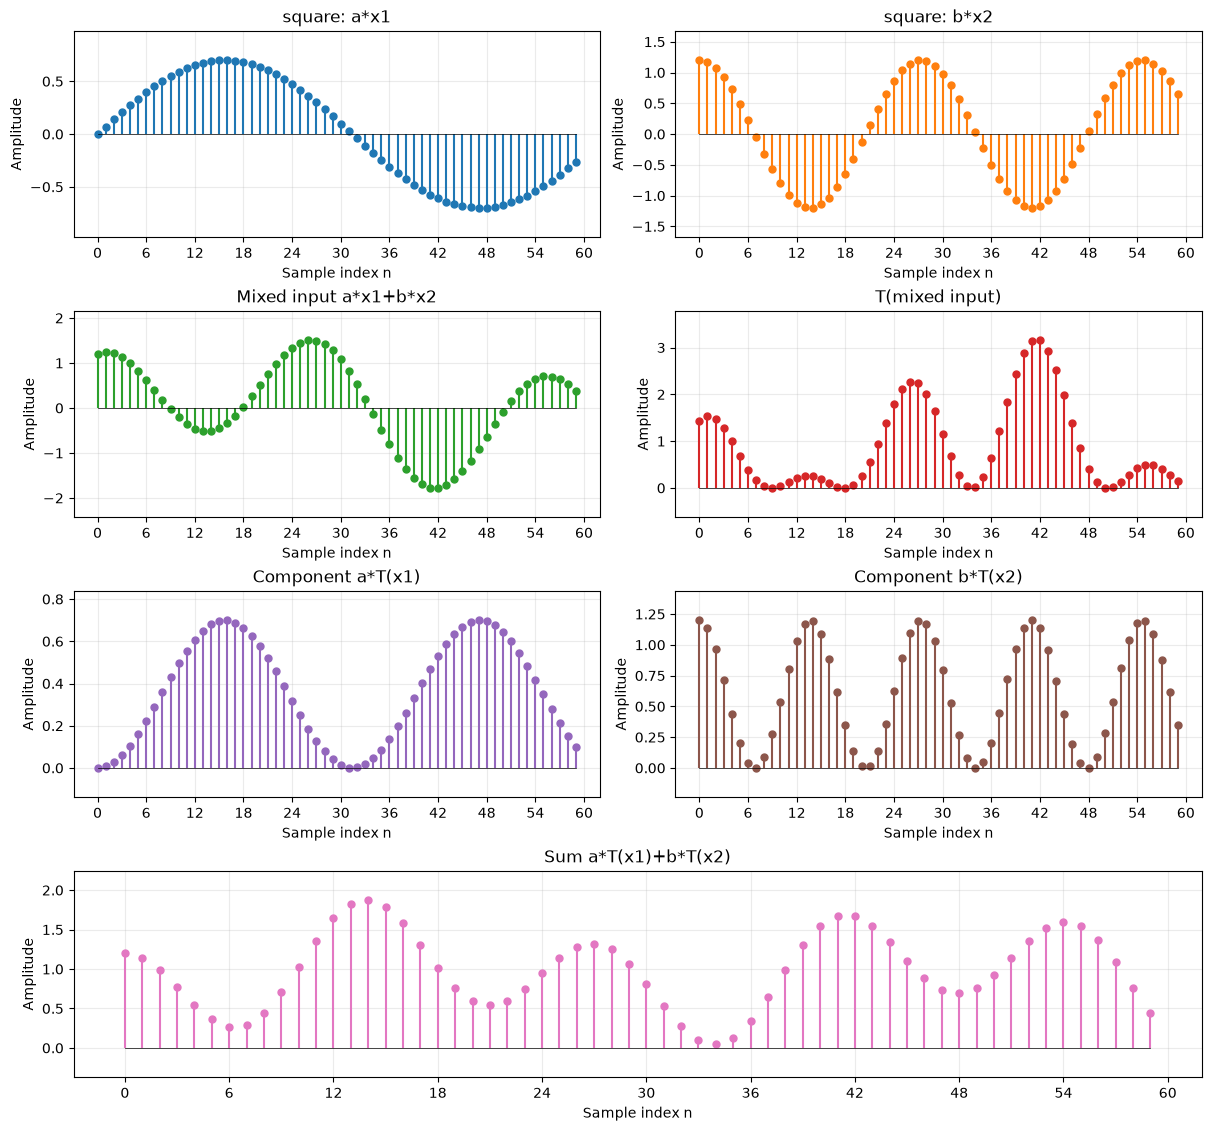

In [20]:
n=np.arange(200); x1=np.sin(0.1*n); x2=np.cos(0.23*n); a,b=0.7,1.2
for name,T in {'gain':lambda x:3*x,'square':lambda x:x*x}.items():
    lhs=T(a*x1+b*x2); rhs=a*T(x1)+b*T(x2)
    print(name,'叠加误差：',err(lhs,rhs))
    graph(n[:60],{f'{name}: a*x1':(a*x1)[:60],f'{name}: b*x2':(b*x2)[:60],
        'Mixed input a*x1+b*x2':(a*x1+b*x2)[:60], 'T(mixed input)':lhs[:60],
        'Component a*T(x1)':(a*T(x1))[:60], 'Component b*T(x2)':(b*T(x2))[:60],
        'Sum a*T(x1)+b*T(x2)':rhs[:60]},kind='discrete')

**观察与应用：** 线性放大器允许分轨处理再混音；平方器会产生交叉项，形成失真与新频率。把平方改成限幅 np.clip(x,-0.5,0.5)，观察过载。

## 实验 2：时不变性：设备是否随时钟改变

**要理解什么：** 理解时不变性检查的是处理规律是否随输入到达时间改变。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{x(t-t_0)\xrightarrow{T}y(t-t_0)} \\[6pt]
\text{离散： }\boxed{T\{x[n-d]\}=y[n-d]},\quad y=T\{x\}
\end{gathered}
$$

**符号与代码怎样对应：** `delay(x,d)` 代表输入延迟 d，零填充而不回绕。`lhs=T(delay(x,d))` 是先延迟再处理，`rhs=delay(T(x),d)` 是先处理再延迟。测试固定滤波器与增益 (1+n/50) 随时钟变化的系统。

**怎样读图、怎样判断结果：** 固定滤波器两种顺序结果一致，时钟增益则不同。原输入和延迟输入只解释测试构造，真正判断的是最后两幅输出图与打印误差。

**先预测，再改参数：** 改变 d，观察时钟增益的误差是否变化；固定滤波器仍应通过。

**本例设置与适用范围：**

覆盖第一节时不变。用零填充实现延迟，比较 $T(Dx)$ 和 $D(Tx)$；避免 np.roll 的首尾回绕。

fixed filter 延迟误差： 0.0


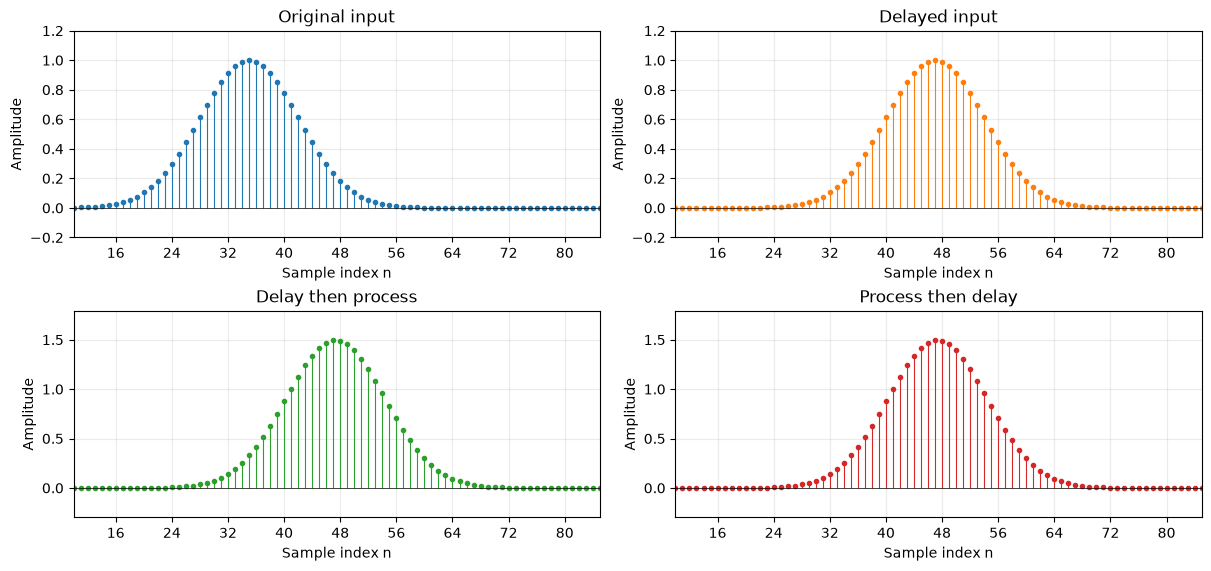

clock gain 延迟误差： 0.24


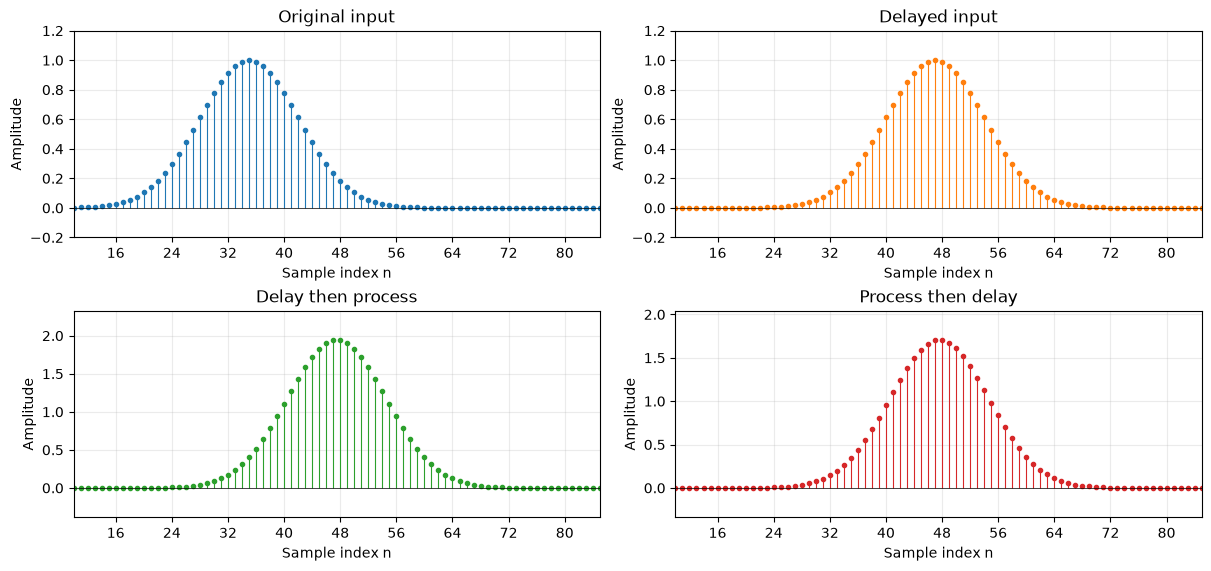

In [21]:
def delay(x,d):
    return np.r_[np.zeros(d),x[:-d]] if d else x.copy()
d=12; n=np.arange(120); x=np.exp(-((n-35)/10)**2)
for name,T in {'fixed filter':lambda x:signal.lfilter([1,0.5],[1],x),
               'clock gain':lambda x:(1+n/50)*x}.items():
    lhs=T(delay(x,d)); rhs=delay(T(x),d)
    print(name,'延迟误差：',err(lhs,rhs))
    graph(n,{'Original input':x,'Delayed input':delay(x,d),
             'Delay then process':lhs,'Process then delay':rhs},kind='discrete',xlim=(10,85))

**观察与应用：** 固定滤波器对早晚到来的同样输入使用同样规律；时钟增益则不同。设备老化、自动增益随时间调整时，不能直接套用单一固定卷积模型。

## 实验 3：LTI 与记忆：当前输入相同，输出是否相同

**要理解什么：** 理解无记忆：当前输入相同，过去不同，当前输出还能否不同。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{h[n]=K\delta[n]}\ \Longleftrightarrow\ \boxed{y[n]=Kx[n]} \\[6pt]
 h[n]=\delta[n]+0.5\delta[n-1]\Rightarrow y[n]=x[n]+0.5x[n-1]
\end{gathered}
$$

**符号与代码怎样对应：** 两条输入在 now=7 时都为零，但 x2[6]=2、x1[6]=0。分别代入无记忆增益器 K=3 和有记忆的两抽头滤波器。

**怎样读图、怎样判断结果：** 无记忆系统在 now 输出都为 0；有记忆系统分别为 0 和 1。图中 n=7 处的余波来自过去的 n=6，并非当前新输入。该 h 条件适用于 LTI 系统。

**先预测，再改参数：** 把过去脉冲从 n=6 移到 n=5，检查这个只有一格记忆的系统在 now=7 是否还受影响。

**本例设置与适用范围：**

覆盖第二、四节。LTI 无记忆的充要条件为 $h[n]=K\delta[n]$。构造当前值相同、过去不同的两条输入。

memoryless 当前输入： 0.0 0.0 当前输出： 0.0 0.0
memory 当前输入： 0.0 0.0 当前输出： 0.0 1.0


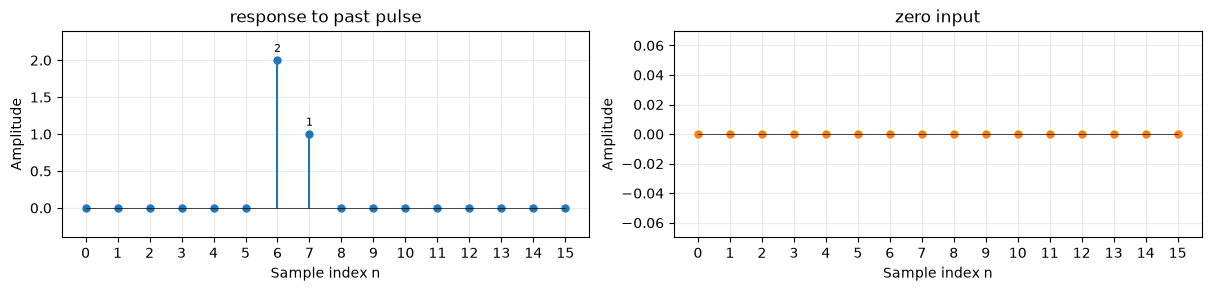

[<Axes: title={'center': 'response to past pulse'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'zero input'}, xlabel='Sample index n', ylabel='Amplitude'>]

In [22]:
x1=np.zeros(15); x2=x1.copy(); x2[6]=2; now=7
for name,h in {'memoryless':[3.],'memory':[1.,0.5]}.items():
    y1=np.convolve(x1,h); y2=np.convolve(x2,h)
    print(name,'当前输入：',x1[now],x2[now],'当前输出：',y1[now],y2[now])
graph(np.arange(16),{'response to past pulse':np.convolve(x2,[1,0.5]),'zero input':np.zeros(16)},kind='discrete')

**观察与应用：** 回声和电容保存了过去的影响；当前值相同不足以决定输出。增益器只依赖当前输入，适合逐点校准。

## 实验 4：串联、并联与模块合并

**要理解什么：** 理解串联等于卷积冲激响应，并联等于相加冲激响应。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{h_{\mathrm{eq}}=h_1*h_2},\quad (x*h_1)*h_2=x*(h_1*h_2) \\[6pt]
\boxed{h_{\mathrm{eq}}=h_1+h_2},\quad x*h_1+x*h_2=x*(h_1+h_2)
\end{gathered}
$$

**符号与代码怎样对应：** `serial` 是逐个经过两个模块；`equivalent` 先合并 h1、h2 再处理。并联部分两条分量是同一输入分别经过 h1 与 h2，`parallel` 是输出相加。

**怎样读图、怎样判断结果：** 串联图对应位置相等，并联两分量逐点相加得到总和；三个打印误差应接近零。结论要求模块是 LTI 且初始状态按本实验取零。

**先预测，再改参数：** 修改任意一个模块系数，重新比较等效系统是否仍一致。

**本例设置与适用范围：**

覆盖第三节。串联 $h_{eq}=h_1*h_2$，并联 $h_{eq}=h_1+h_2$。

串联等效误差： 2.220446049250313e-16
交换串联顺序误差： 4.440892098500626e-16
并联等效误差： 4.440892098500626e-16


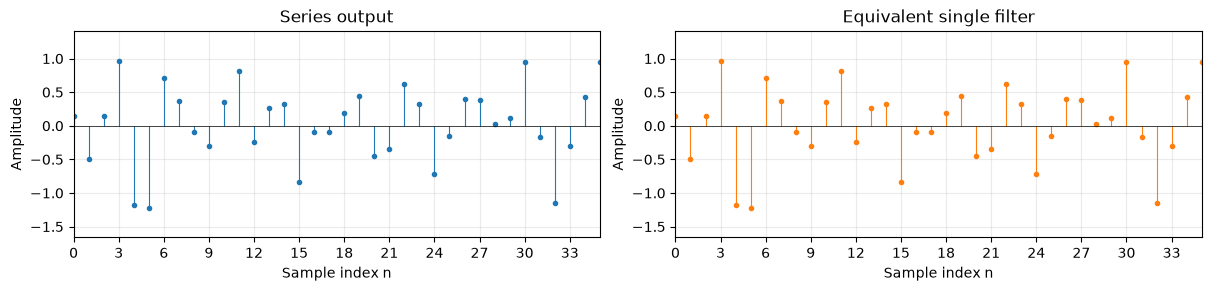

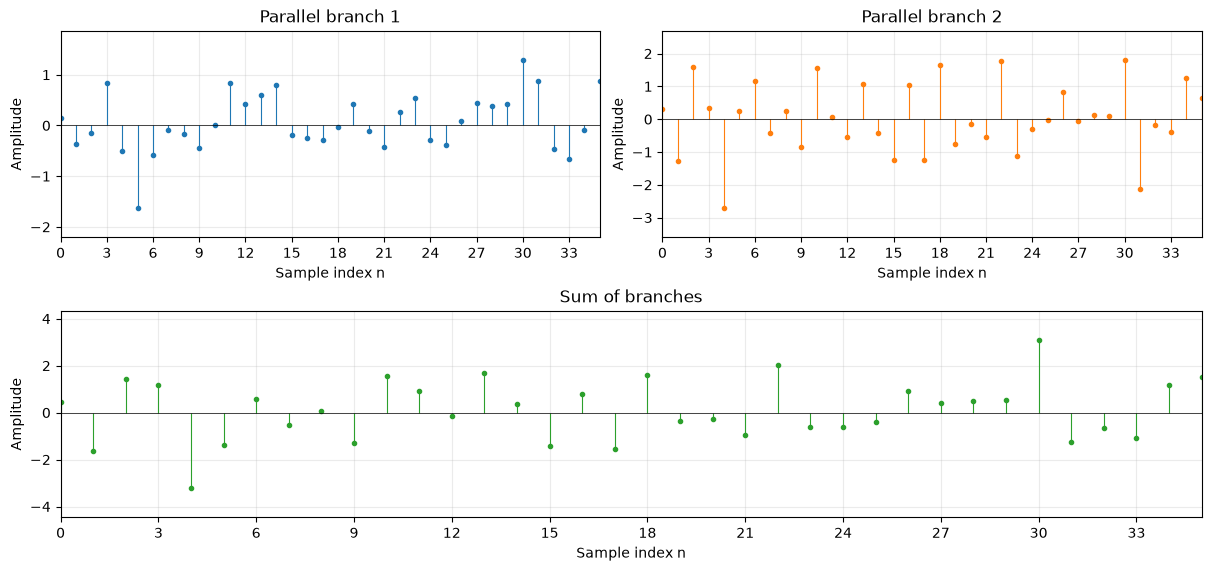

[<Axes: title={'center': 'Parallel branch 1'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'Parallel branch 2'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'Sum of branches'}, xlabel='Sample index n', ylabel='Amplitude'>]

In [23]:
x=rng.normal(size=100); h1=np.array([0.5,0.5]); h2=np.array([1.,-0.8])
serial=np.convolve(np.convolve(x,h1),h2)
equivalent=np.convolve(x,np.convolve(h1,h2))
parallel=np.convolve(x,h1)+np.convolve(x,h2)
print('串联等效误差：',err(serial,equivalent))
print('交换串联顺序误差：',err(serial,np.convolve(np.convolve(x,h2),h1)))
print('并联等效误差：',err(parallel,np.convolve(x,h1+h2)))
graph(np.arange(len(serial)),{'Series output':serial,'Equivalent single filter':equivalent},kind='discrete',xlim=(0,35))
graph(np.arange(len(parallel)),{'Parallel branch 1':np.convolve(x,h1),
    'Parallel branch 2':np.convolve(x,h2),'Sum of branches':parallel},kind='discrete',xlim=(0,35))

**观察与应用：** 平滑后差分可用于变化检测，并联可组合原信号与补偿信号。交换次序的结论依赖 LTI 条件；带限幅或内部饱和的设备需要另行分析。

## 实验 5：因果性：实时平滑与离线居中平滑

**要理解什么：** 理解因果性：当前输出能否被未来输入改变。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{h[n]=0,\quad n<0} \\[6pt]
\boxed{y[n]=\sum_{k=-\infty}^{n}x[k]h[n-k]}
\end{gathered}
$$

**符号与代码怎样对应：** 两条记录在 n0=40 及以前相同，x2 只在未来 41 至 44 处增加脉冲。因果平均只取当前与过去；居中平均还用到未来 4 个样本。

**怎样读图、怎样判断结果：** 改变未来后，因果输出在 n0 仍为 0；居中平均在 n0 已非零。图上“事件之前的反应”正是未来样本的贡献，不是预测能力。

**先预测，再改参数：** 改变 M 为其他奇数，计算居中平滑需要等待的未来样本数 (M−1)/2。

**本例设置与适用范围：**

覆盖第五节。两条记录在时刻 $n_0$ 及以前完全一样，只改变未来；看当前输出是否受影响。

causal 改变未来前后当前输出： 0.0 0.0
centered 改变未来前后当前输出： 0.0 0.4444444444444444


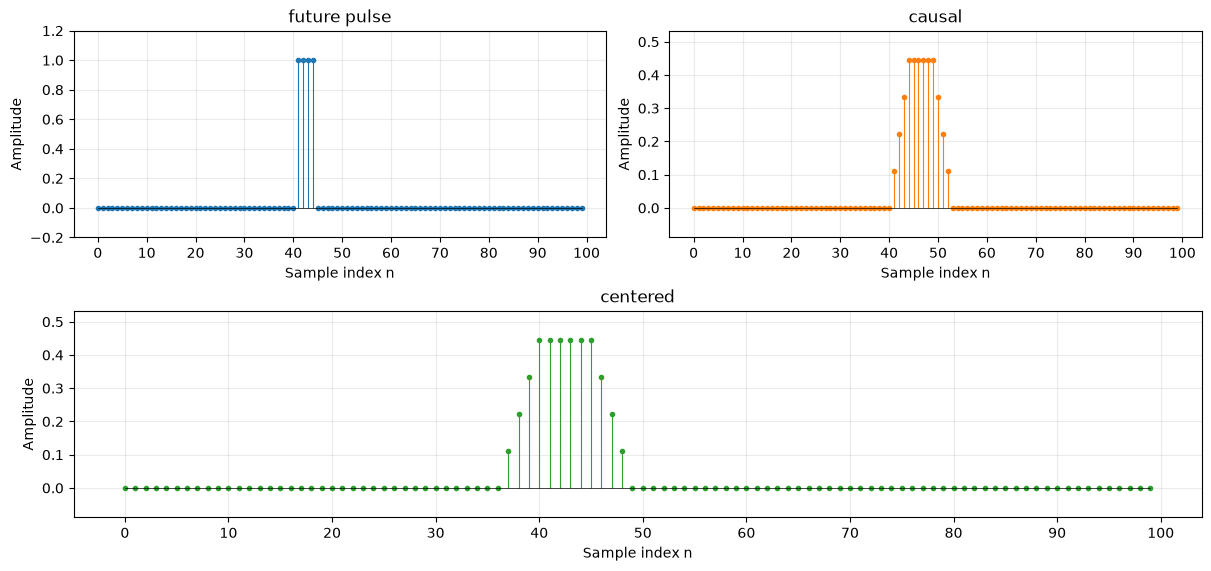

[<Axes: title={'center': 'future pulse'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'causal'}, xlabel='Sample index n', ylabel='Amplitude'>,
 <Axes: title={'center': 'centered'}, xlabel='Sample index n', ylabel='Amplitude'>]

In [24]:
n=np.arange(100); n0=40; x1=np.zeros(100); x2=x1.copy(); x2[n0+1:n0+5]=1
M=9
causal=lambda x:signal.lfilter(np.ones(M)/M,[1],x)
centered=lambda x:np.convolve(x,np.ones(M)/M,mode='same')
for name,T in {'causal':causal,'centered':centered}.items():
    print(name,'改变未来前后当前输出：',T(x1)[n0],T(x2)[n0])
graph(n,{'future pulse':x2,'causal':causal(x2),'centered':centered(x2)},kind='discrete')

**观察与应用：** 居中平滑在事件之前已有响应，因为用到了未来样本；适合离线处理。实时系统可等待 4 个样本再输出居中结果，但这会引入延迟。

## 实验 6：BIBO 稳定性与累加器

**要理解什么：** 理解有界输入不一定产生有界输出；从 h 的绝对可和性判断稳定。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{\sum_{n=-\infty}^{+\infty}|h[n]|<\infty} \\[6pt]
\boxed{\int_{-\infty}^{+\infty}|h(t)|\,dt<\infty} \\[6pt]
 |y[n]|\le M_x\sum_k|h[k]|
\end{gathered}
$$

**符号与代码怎样对应：** 各系统均用 x[n]=u[n] 测试，故输入幅值不超过 1；h[n]=αⁿu[n]，α=1 是笔记的累加器。代码只能算有限项绝对和；一般结论由几何级数给出：|α|<1 时总和为 1/(1−|α|)。

**怎样读图、怎样判断结果：** α=0.7 与 −0.9 的输出保持有限，α=1 的输出为 n+1，α=1.03 进一步增长。有限时长图只是例证；不能把截断和有限当作无限和收敛的证明。

**先预测，再改参数：** 改用 α=−1，再把输入改为 (−1)ⁿ；观察为什么测试一种常值输入不足以判断所有有界输入。

**本例设置与适用范围：**

覆盖第六、八节。因果 $h[n]=\alpha^n u[n]$ 在 $|\alpha|<1$ 时绝对可和；累加器 $\alpha=1$ 对常值有界输入产生持续增长。

alpha=0.7: 截断 sum|h|=3.33, max|y|=3.33
alpha=1.0: 截断 sum|h|=80.00, max|y|=80.00
alpha=1.03: 截断 sum|h|=321.36, max|y|=321.36
alpha=-0.9: 截断 sum|h|=10.00, max|y|=1.00


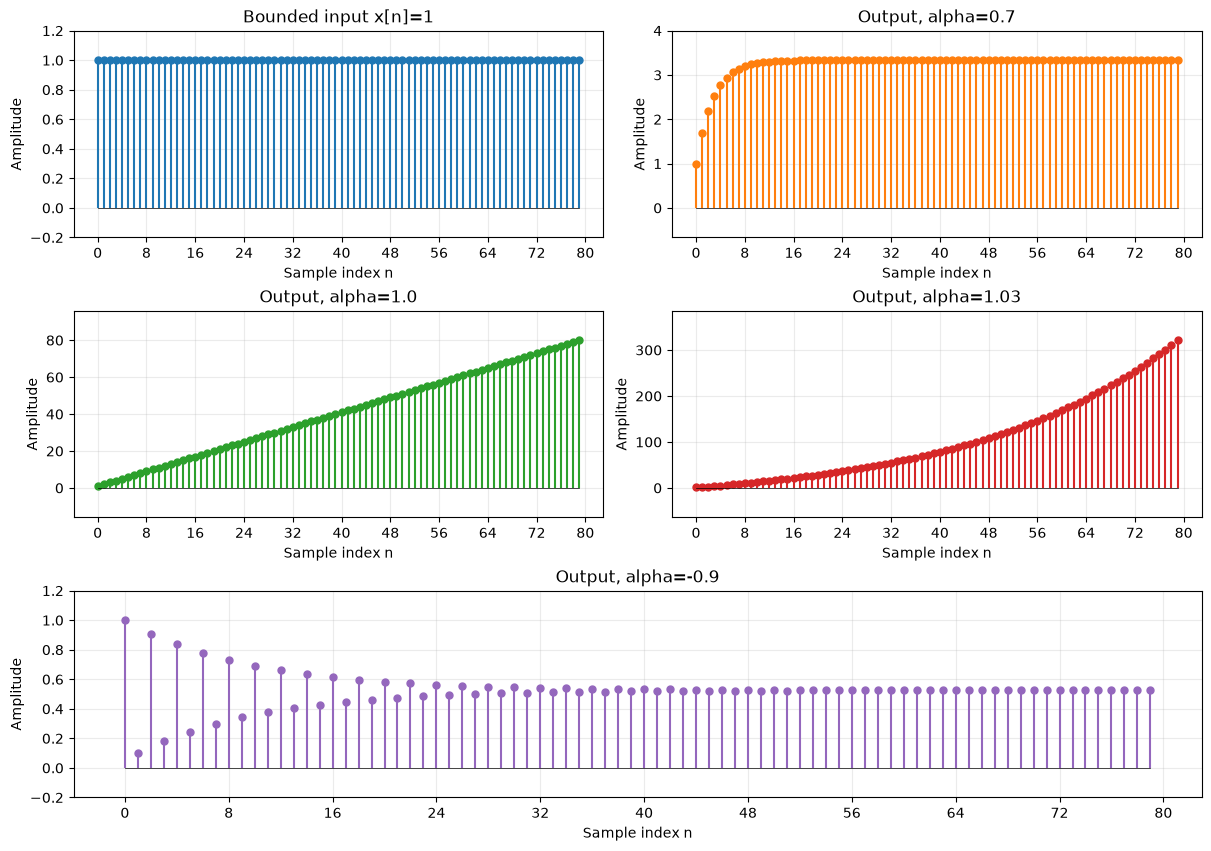

连续 h=exp(-at)u(t) 的绝对积分： 0.5


In [25]:
n=np.arange(80); x=np.ones(len(n)); curves={'Bounded input x[n]=1':x}
for alpha in [0.7,1.,1.03,-0.9]:
    y=signal.lfilter([1],[1,-alpha],x); h=alpha**n
    print(f'alpha={alpha}: 截断 sum|h|={np.sum(abs(h)):.2f}, max|y|={max(abs(y)):.2f}')
    curves[f'Output, alpha={alpha}']=y
graph(n,curves,kind='discrete')
a=2.; print('连续 h=exp(-at)u(t) 的绝对积分：',1/a)

**观察与应用：** 累加器可统计累计流量，但微小传感器偏置也会无限积累。有限仿真无法证明稳定性，要结合几何级数或绝对积分条件。alpha=-1 时常值输入未必暴涨，需选择交替符号输入作反例。

## 实验 7：可逆性、累加器逆系统与噪声

**要理解什么：** 理解可逆要求恢复原输入，而恢复操作可能突出测量噪声。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{h*h^{-1}=\delta} \\[6pt]
 y[n]=\sum_{k=-\infty}^{n}x[k]\Rightarrow\boxed{x[n]=y[n]-y[n-1]} \\[6pt]
 h^{-1}[n]=\delta[n]-\delta[n-1]
\end{gathered}
$$

**符号与代码怎样对应：** `cumsum(x)` 模拟累加器，初始累计值 y[−1]=0；`diff([0,y])` 实现逆系统。对精确累计值与加入测量噪声的累计值分别求差分，比较恢复结果。

**怎样读图、怎样判断结果：** 无噪声逆输出应与 x 一致；有噪声则出现抖动，打印 RMSE 度量恢复误差。平方器 T(1)=T(−1) 展示另一个情况：不同输入变成同一输出，不能唯一求逆。

**先预测，再改参数：** 增大累计读数噪声标准差，观察差分后的噪声；思考初始累计值未知时第一个恢复样本为什么不确定。

**本例设置与适用范围：**

覆盖第七、八节。累加后差分恢复输入；逆系统可存在而对测量误差敏感。假定已知初始累计值为 0。

无噪声恢复误差： 4.773959005888173e-15
有噪声恢复 RMSE： 0.13425041603593954


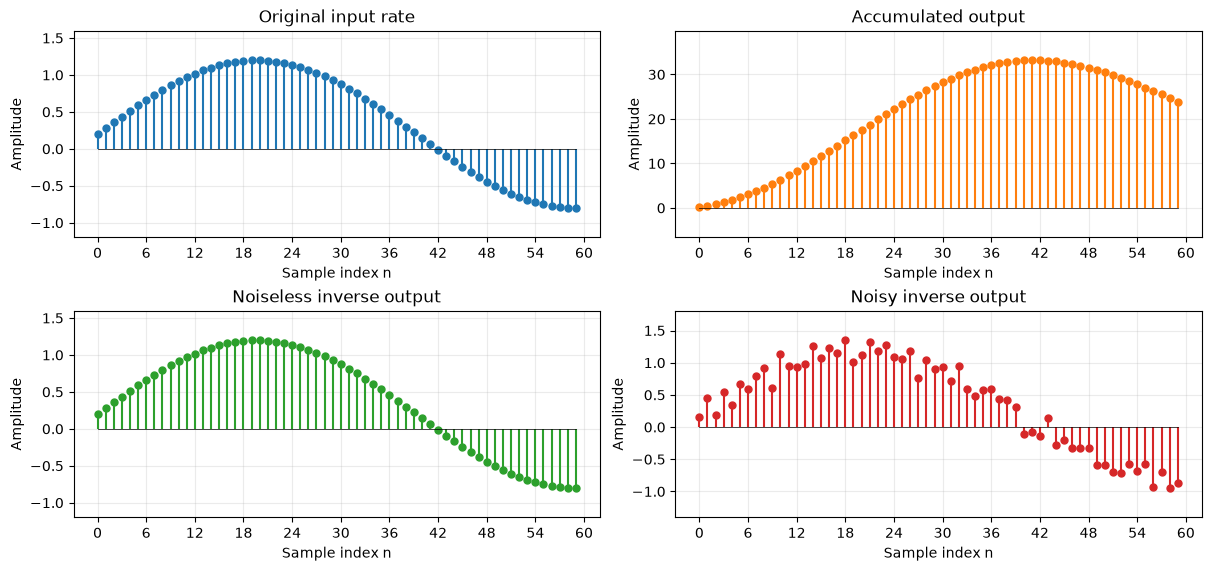

平方器：T(1)= 1 T(-1)= 1


In [26]:
n=np.arange(200); x=0.2+np.sin(0.08*n); y=np.cumsum(x)
restored=np.diff(np.r_[0,y]); assert np.allclose(restored,x)
noisy_y=y+0.1*rng.normal(size=len(y))
restored_noisy=np.diff(np.r_[0,noisy_y])
print('无噪声恢复误差：',err(x,restored))
print('有噪声恢复 RMSE：',np.sqrt(np.mean((restored_noisy-x)**2)))
graph(n[:60],{'Original input rate':x[:60],'Accumulated output':y[:60],
    'Noiseless inverse output':restored[:60],'Noisy inverse output':restored_noisy[:60]},kind='discrete')
# 平方会丢失符号，因此不能唯一求逆。
print('平方器：T(1)=',1**2,'T(-1)=',(-1)**2)

**观察与应用：** 可以从累计电表读数求每段用量；差分会突出高频读数噪声。平方器把不同输入映成同一个值，丢失信息后无法唯一恢复。

## 实验 8：阶跃响应测冲激响应

**要理解什么：** 理解测一次阶跃响应，为什么可以用差分或求导恢复冲激响应。

**要验证的数学形式（对照[原笔记](../../../系统的性质.md)）：**

$$
\begin{gathered}
\boxed{h(t)=\frac{ds(t)}{dt}} \\[6pt]
\boxed{h[n]=s[n]-s[n-1]} \\[6pt]
 u\xrightarrow{T}s,\quad\delta\xrightarrow{T}h
\end{gathered}
$$

**符号与代码怎样对应：** 离散 `s` 用解析阶跃响应，`diff([0,s])` 表示 s[n]−s[n−1]，补入的 0 是 s[−1]。连续 `gradient` 近似 ds/dt，参考是 exp(−at)。

**怎样读图、怎样判断结果：** 离散恢复应等于 αⁿ；连续内部点误差应小，端点差分精度与内部不同。s 是系统输出，u 是输入，不能把两者混为同一个阶跃。

**先预测，再改参数：** 减小连续时间步长观察误差；给 s 添加少量噪声，预测求导估计会更抖。

**本例设置与适用范围：**

覆盖第九节。$h[n]=s[n]-s[n-1]$；连续情况下 $h(t)=s\prime(t)$。注意 $s[-1]=0$。

连续内部点微分误差： 1.6500913069372736e-05


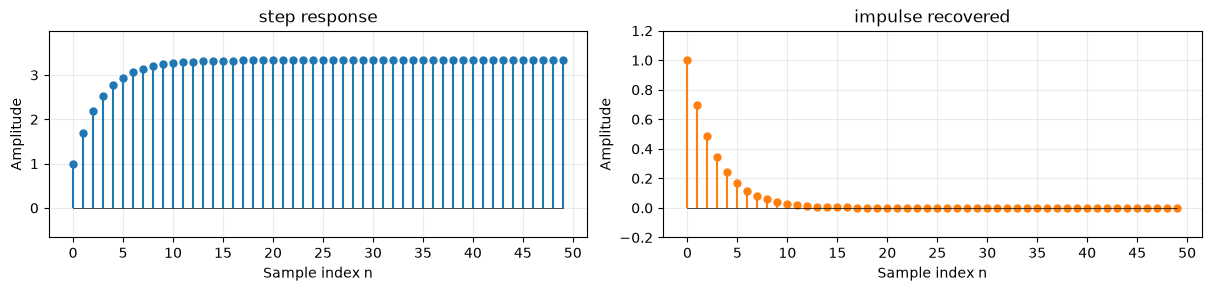

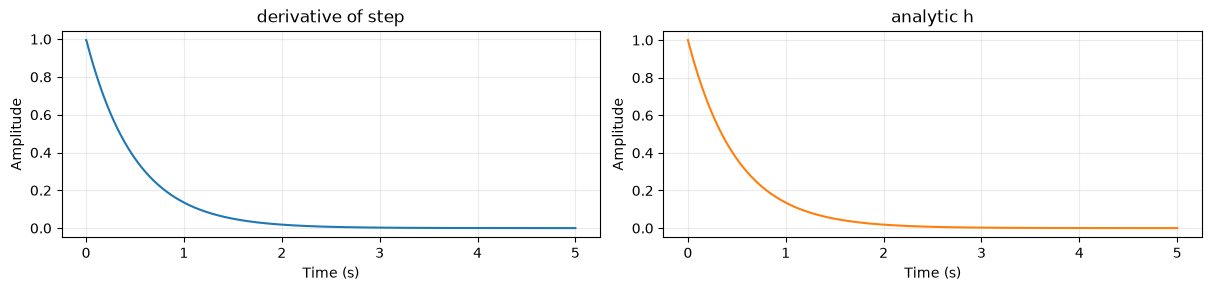

[<Axes: title={'center': 'derivative of step'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'analytic h'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [27]:
alpha=0.7; n=np.arange(50)
s=(1-alpha**(n+1))/(1-alpha); h=np.diff(np.r_[0,s])
assert np.allclose(h,alpha**n)
t=np.linspace(0,5,1001); a=2.; s_ct=(1-np.exp(-a*t))/a
h_ct=np.gradient(s_ct,t)
print('连续内部点微分误差：',err(h_ct[1:-1],np.exp(-a*t[1:-1])) )
graph(n,{'step response':s,'impulse recovered':h},kind='discrete')
graph(t,{'derivative of step':h_ct,'analytic h':np.exp(-a*t)},'Time (s)',kind='continuous')

**观察与应用：** 实际设备难以输入理想冲激，可以输入开关阶跃后求导来估计动态响应。测量噪声经求导会放大，实际应用常先拟合或平滑。

## 实验记录

每次选一个参数，记录：原值、新值、图像变化、指标变化、可以解决的实际问题、模型的适用条件。先预测结果，再运行验证。